# Partie 1 — Modèles probabilistes et estimation
**Binôme : Amjad AAYD et [information masquée] — [information masquée] — 6 octobre 2026**

Enseignant : [information masquée]. Groupe : à compléter.
Source : Introduction aux modèles génératifs, huit pages, 20 avril 2026. Résultats exécutés, graines fixées.


In [1]:
%matplotlib inline
import sys, json, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import sklearn
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)
torch.set_default_dtype(torch.float64)
torch.set_num_threads(2)
torch.manual_seed(42)
rng = np.random.default_rng(42)
figdir = Path("figures")
figdir.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2})
def save(fig, name):
    fig.savefig(figdir / (name + ".png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| PyTorch", torch.__version__, "| scikit-learn", sklearn.__version__)
print("Calcul CPU, float64, deux threads ; graine =", 42)


Python 3.12.10 | NumPy 2.3.5 | PyTorch 2.12.0.dev20260408+cu128 | scikit-learn 1.8.0
Calcul CPU, float64, deux threads ; graine = 42


## 1.1 Bernoulli : estimation directe et sigmoïde
Avec $\bar x$ la moyenne, la NLL moyenne est $-\bar x\log\theta-(1-\bar x)\log(1-\theta)$. Son gradient en θ vaut $(\theta-\bar x)/(\theta(1-\theta))$. Le MLE est $\bar x$. Une mise à jour directe doit respecter $(0,1)$ ; la sigmoïde θ=σ(φ) impose cette contrainte sans clamp. En φ, le gradient devient θ−x̄. La différence entre vrai paramètre et MLE est une fluctuation d'échantillonnage, pas nécessairement une erreur d'optimisation.

Bernoulli : vrai = 0.7 MLE = 0.696 direct = 0.6959999999999998 sigmoïde = 0.696


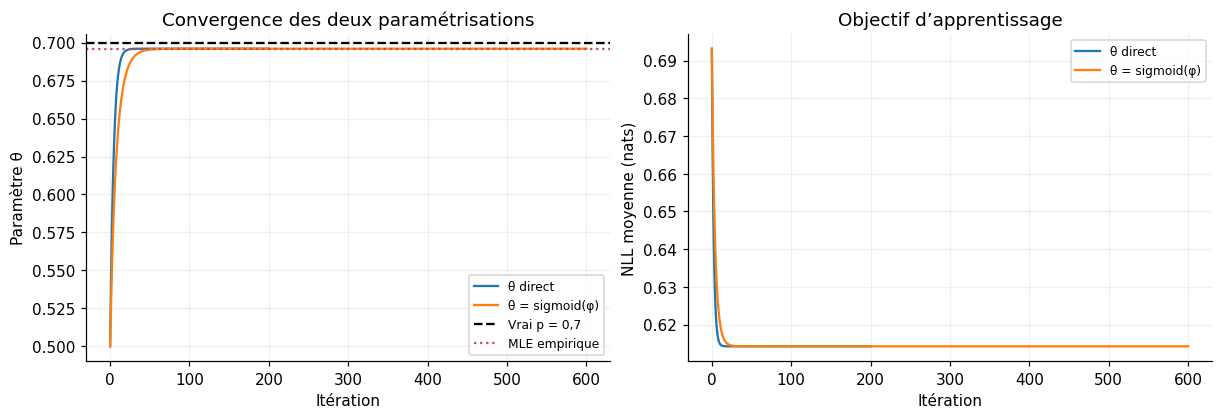

In [2]:
xb = torch.tensor(rng.binomial(1, .7, 1000), dtype=torch.float64)
true_p, p_mle = .7, xb.mean().item()
def nll_b(theta):
    return -(xb * torch.log(theta) + (1-xb) * torch.log1p(-theta)).mean()
def fit_bernoulli(reparam, steps, lr):
    param = torch.nn.Parameter(torch.tensor(0.0 if reparam else .5))
    optim = torch.optim.SGD([param], lr=lr)
    history=[]
    for step in range(steps+1):
        theta = torch.sigmoid(param) if reparam else param
        loss = nll_b(theta)
        history.append([step, theta.item(), loss.item()])
        if step == steps: break
        optim.zero_grad(); loss.backward(); optim.step()
        if not reparam:
            with torch.no_grad(): param.clamp_(1e-6, 1-1e-6)
    return np.array(history)
hb = fit_bernoulli(False, 200, .05)
hsig = fit_bernoulli(True, 600, .5)
assert abs(hb[-1,1]-p_mle) < 1e-6
assert abs(hsig[-1,1]-p_mle) < 1e-6
assert np.all((hb[:,1]>0)&(hb[:,1]<1)) and np.all((hsig[:,1]>0)&(hsig[:,1]<1))
print('Bernoulli : vrai =',true_p,'MLE =',p_mle,'direct =',hb[-1,1],'sigmoïde =',hsig[-1,1])
fig,ax=plt.subplots(1,2,figsize=(11,3.7),layout='constrained')
for h,label in [(hb,'θ direct'),(hsig,'θ = sigmoid(φ)')]:
    ax[0].plot(h[:,0],h[:,1],label=label);ax[1].plot(h[:,0],h[:,2],label=label)
ax[0].axhline(true_p,color='black',ls='--',label='Vrai p = 0,7')
ax[0].axhline(p_mle,color='#c44e52',ls=':',label='MLE empirique')
ax[0].set(xlabel='Itération',ylabel='Paramètre θ',title='Convergence des deux paramétrisations')
ax[1].set(xlabel='Itération',ylabel='NLL moyenne (nats)',title='Objectif d’apprentissage')
for a in ax:a.legend(fontsize=8)
save(fig,'01_bernoulli')


## 1.2 Gaussienne univariée
NLL(μ,σ) = log σ + ½log(2π) + moyenne((x−μ)²)/(2σ²). On utilise σ=softplus(ρ)+ε avec ε=10⁻⁶ ; μ et ρ sont optimisés par descente de gradient (SGD). Le MLE de σ utilise le diviseur N, et non N−1. Il sert de contrôle numérique distinct des valeurs vraies.

Gaussienne 1D : vrai (2.0, 1.5) MLE (1.9596928721511304, 1.519229528043927) gradient [1.95969 1.51923]


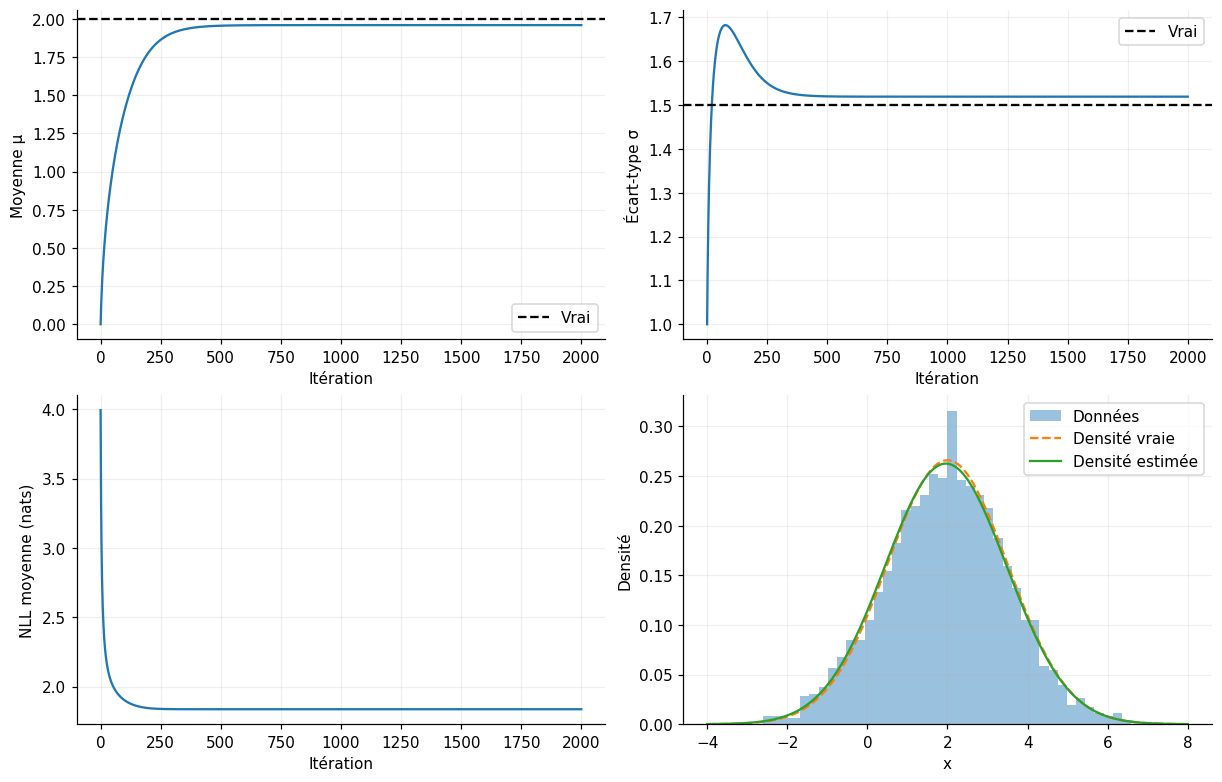

In [3]:
xu = torch.tensor(rng.normal(2.,1.5,2000))
mu = torch.nn.Parameter(torch.tensor(0.))
rho = torch.nn.Parameter(torch.tensor(math.log(math.expm1(1.))))
optim = torch.optim.SGD([mu,rho],lr=.03)
hu=[]
for step in range(2001):
    sigma = F.softplus(rho)+1e-6
    loss = torch.log(sigma)+.5*math.log(2*math.pi)+((xu-mu)**2).mean()/(2*sigma**2)
    hu.append([step,mu.item(),sigma.item(),loss.item()])
    if step==2000:break
    optim.zero_grad();loss.backward();optim.step()
hu=np.array(hu)
mu_mle, sigma_mle = xu.mean().item(), xu.std(correction=0).item()
assert np.max(np.abs(hu[-1,1:3]-[mu_mle,sigma_mle]))<1e-5
assert np.all(hu[:,2]>0)
print('Gaussienne 1D : vrai',(2.,1.5),'MLE',(mu_mle,sigma_mle),'gradient',hu[-1,1:3])
fig,ax=plt.subplots(2,2,figsize=(11,7),layout='constrained')
for a,col,val,title in [(ax[0,0],1,2.,'Moyenne μ'),(ax[0,1],2,1.5,'Écart-type σ')]:
    a.plot(hu[:,0],hu[:,col]);a.axhline(val,color='black',ls='--',label='Vrai');a.set(xlabel='Itération',ylabel=title);a.legend()
ax[1,0].plot(hu[:,0],hu[:,3]);ax[1,0].set(xlabel='Itération',ylabel='NLL moyenne (nats)')
grid=np.linspace(-4,8,400)
def normal_pdf(t,m,s):return np.exp(-.5*((t-m)/s)**2)/(s*np.sqrt(2*np.pi))
ax[1,1].hist(xu.numpy(),bins=40,density=True,alpha=.45,label='Données')
ax[1,1].plot(grid,normal_pdf(grid,2.,1.5),ls='--',label='Densité vraie')
ax[1,1].plot(grid,normal_pdf(grid,*hu[-1,1:3]),label='Densité estimée')
ax[1,1].set(xlabel='x',ylabel='Densité');ax[1,1].legend()
save(fig,'02_gaussienne_univariee')


## 1.2 Gaussienne multivariée en dimension 3
Σ=LLᵀ, avec L triangulaire inférieure et diagonale softplus+ε. La NLL moyenne est (d/2)log(2π)+Σj log Ljj + ½ moyenne(||L⁻¹(x−μ)||²). On résout un système triangulaire plutôt que d'inverser explicitement Σ ; log|Σ|=2Σj log Ljj. Cette construction garantit une covariance symétrique définie positive. Les références empiriques sont moyenne et covariance /N.

Moyenne vraie / estimée / MLE :
[ 1.  -2.   0.5]
[ 1.03371 -1.96027  0.5202 ]
[ 1.03371 -1.96027  0.5202 ]
Covariance vraie :
 [[1.  0.5 0.2]
 [0.5 2.  0.4]
 [0.2 0.4 1.5]] 
Covariance estimée :
 [[0.98148 0.45822 0.1533 ]
 [0.45822 1.95289 0.31974]
 [0.1533  0.31974 1.49353]]


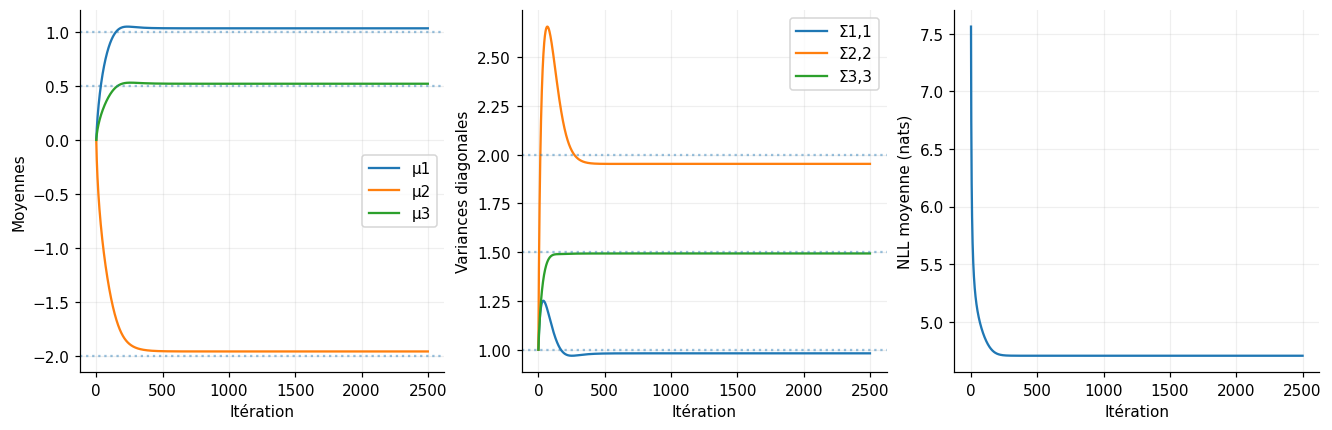

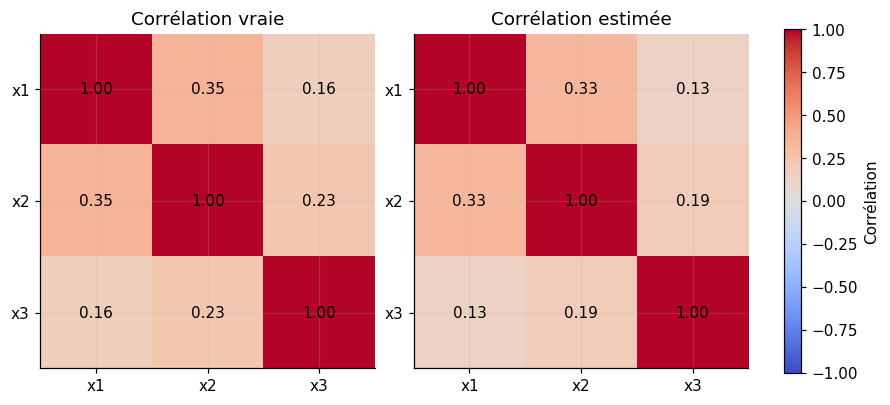

In [4]:
mu_true=np.array([1.,-2.,.5])
cov_true=np.array([[1.,.5,.2],[.5,2.,.4],[.2,.4,1.5]])
assert np.linalg.eigvalsh(cov_true).min()>0
X3=rng.multivariate_normal(mu_true,cov_true,2000)
xt=torch.tensor(X3)
mu3=torch.nn.Parameter(torch.zeros(3))
rawL=torch.nn.Parameter(torch.eye(3)*math.log(math.expm1(1.)))
def cholesky_param(raw):
    return torch.tril(raw,diagonal=-1)+torch.diag(F.softplus(torch.diagonal(raw))+1e-6)
optim=torch.optim.SGD([mu3,rawL],lr=.03)
h3=[]
for step in range(2501):
    L=cholesky_param(rawL)
    centered=(xt-mu3).T
    solved=torch.linalg.solve_triangular(L,centered,upper=False)
    loss=1.5*math.log(2*math.pi)+torch.log(torch.diagonal(L)).sum()+.5*solved.square().sum(0).mean()
    cov=L@L.T
    h3.append([step,*mu3.detach().numpy(),*cov.diagonal().detach().numpy(),loss.item()])
    if step==2500:break
    optim.zero_grad();loss.backward();optim.step()
h3=np.array(h3)
mu3_est=mu3.detach().numpy();cov3_est=cov.detach().numpy()
mu3_mle=X3.mean(0); xc=X3-mu3_mle;cov3_mle=xc.T@xc/len(X3)
assert np.linalg.eigvalsh(cov3_est).min()>0
assert np.max(np.abs(mu3_est-mu3_mle))<1e-4
assert np.max(np.abs(cov3_est-cov3_mle))<1e-4
print('Moyenne vraie / estimée / MLE :',mu_true,mu3_est,mu3_mle,sep='\n')
print('Covariance vraie :\n',cov_true,'\nCovariance estimée :\n',cov3_est)
fig,ax=plt.subplots(1,3,figsize=(12,3.8),layout='constrained')
for j in range(3):
    ax[0].plot(h3[:,0],h3[:,1+j],label=f'μ{j+1}');ax[0].axhline(mu_true[j],ls=':',alpha=.45)
    ax[1].plot(h3[:,0],h3[:,4+j],label=f'Σ{j+1},{j+1}');ax[1].axhline(cov_true[j,j],ls=':',alpha=.45)
ax[2].plot(h3[:,0],h3[:,-1]);ax[2].set(ylabel='NLL moyenne (nats)')
ax[0].set(ylabel='Moyennes');ax[1].set(ylabel='Variances diagonales')
for a in ax:a.set_xlabel('Itération')
for a in ax[:2]:a.legend()
save(fig,'03_gaussienne_3d_convergence')
def corr(c):return c/np.sqrt(np.outer(np.diag(c),np.diag(c)))
fig,ax=plt.subplots(1,2,figsize=(8,3.6),layout='constrained')
for a,c,title in zip(ax,[corr(cov_true),corr(cov3_est)],['Corrélation vraie','Corrélation estimée']):
    im=a.imshow(c,vmin=-1,vmax=1,cmap='coolwarm');a.set_title(title);a.set_xticks(range(3),['x1','x2','x3']);a.set_yticks(range(3),['x1','x2','x3'])
    for i in range(3):
        for j in range(3):a.text(j,i,f'{c[i,j]:.2f}',ha='center',va='center',color='black')
fig.colorbar(im,ax=ax,label='Corrélation')
save(fig,'04_correlations')


## 1.3 GMM 3D et EM implémenté manuellement
E-step : responsabilités normalisées rᵢk calculées en log avec logsumexp. M-step : Nk, πk, μk et Σk pondérés. Trois initialisations aléatoires sont essayées (poids uniformes, moyennes tirées des observations, covariance globale régulière) ; on conserve celle de plus grande log-vraisemblance finale. Une régularisation diagonale 10⁻⁶ évite les singularités numériques. Critère : gain moyen de log-vraisemblance <10⁻⁶ ou 150 mises à jour.

**Label switching** : permuter les composantes ne change pas la densité. Pour K=3, on teste les six permutations et choisit celle minimisant la distance entre moyennes vraies et estimées avant toute comparaison.

Permutation estimée alignée sur les vraies composantes : (2, 1, 0)
Log-vraisemblances finales des trois essais : [np.float64(-30012.693), np.float64(-30012.693), np.float64(-30012.693)]
Poids vrais / estimés :
[0.25 0.45 0.3 ]
[0.25199 0.44701 0.301  ]
Moyennes vraies / estimées :
[[-4.  0.  2.]
 [ 0.  4. -2.]
 [ 4. -3.  0.]]
[[-3.99026 -0.04757  2.00911]
 [-0.05862  3.98695 -2.02338]
 [ 4.01109 -3.01619  0.02972]]
Covariances vraies / estimées :
[[[ 0.7   0.15  0.  ]
  [ 0.15  0.9   0.1 ]
  [ 0.    0.1   0.6 ]]

 [[ 1.   -0.2   0.1 ]
  [-0.2   0.8   0.  ]
  [ 0.1   0.    0.9 ]]

 [[ 0.8   0.1  -0.1 ]
  [ 0.1   0.6   0.1 ]
  [-0.1   0.1   1.  ]]]
[[[ 0.72536  0.1411   0.00751]
  [ 0.1411   0.88282  0.09731]
  [ 0.00751  0.09731  0.58471]]

 [[ 0.99987 -0.18741  0.0932 ]
  [-0.18741  0.79218  0.00252]
  [ 0.0932   0.00252  0.92386]]

 [[ 0.81318  0.09892 -0.10716]
  [ 0.09892  0.61286  0.09697]
  [-0.10716  0.09697  1.01315]]]


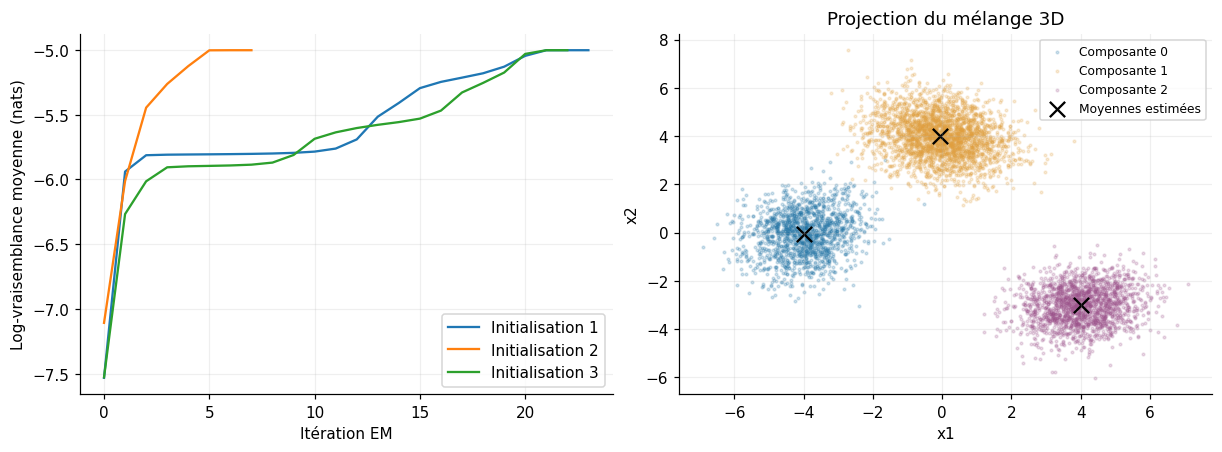

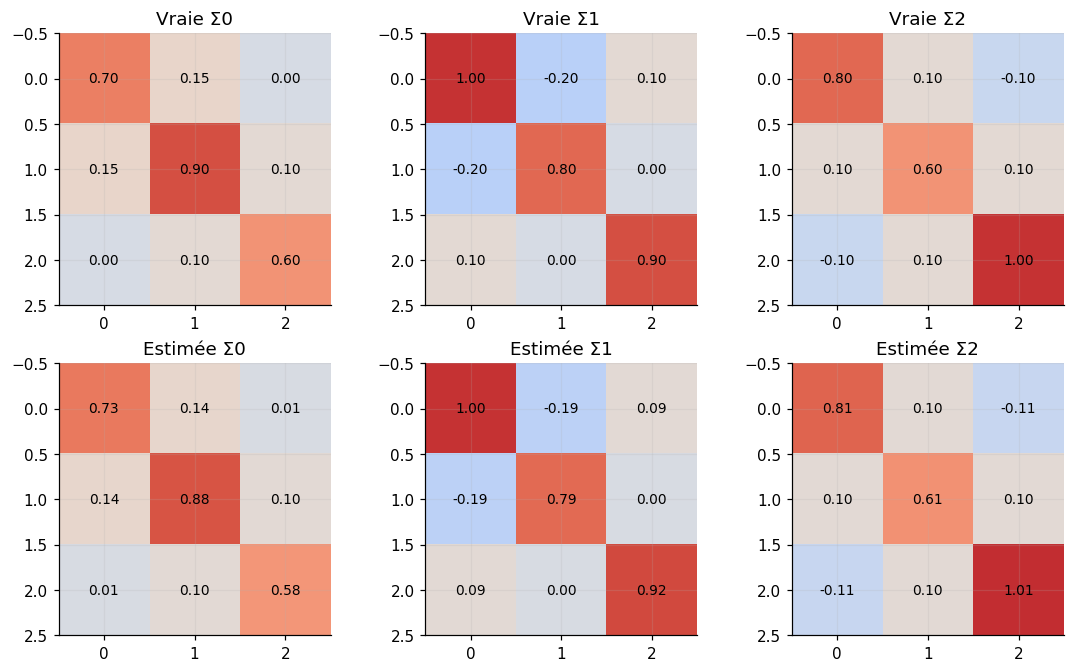

In [5]:
from scipy.special import logsumexp
from itertools import permutations
weights_true=np.array([.25,.45,.30])
means_true=np.array([[-4.,0.,2.],[0.,4.,-2.],[4.,-3.,0.]])
covs_true=np.array([[[.7,.15,0],[.15,.9,.1],[0,.1,.6]],
                    [[1.,-.2,.1],[-.2,.8,0],[.1,0,.9]],
                    [[.8,.1,-.1],[.1,.6,.1],[-.1,.1,1.]]])
z=rng.choice(3,size=6000,p=weights_true)
Xg=np.empty((6000,3))
for k in range(3):Xg[z==k]=rng.multivariate_normal(means_true[k],covs_true[k],sum(z==k))
def log_density(X,mean,cov):
    L=np.linalg.cholesky(cov)
    whiten=np.linalg.solve(L,(X-mean).T)
    return -.5*(X.shape[1]*np.log(2*np.pi)+2*np.log(np.diag(L)).sum()+np.sum(whiten**2,axis=0))
def em_fit(X,seed,max_iter=150,tol=1e-6):
    rs=np.random.default_rng(seed);N,d=X.shape;K=3
    pi=np.ones(K)/K;means=X[rs.choice(N,K,replace=False)].copy()
    global_cov=np.cov(X,rowvar=False,bias=True)+1e-6*np.eye(d)
    covs=np.repeat(global_cov[None,:,:],K,axis=0);history=[]
    for it in range(max_iter+1):
        logits=np.column_stack([np.log(pi[k])+log_density(X,means[k],covs[k]) for k in range(K)])
        lognorm=logsumexp(logits,axis=1);ll=float(lognorm.sum());history.append(ll)
        resp=np.exp(logits-lognorm[:,None])
        assert np.allclose(resp.sum(1),1)
        if it>0 and abs(history[-1]-history[-2])/N<tol:break
        if it==max_iter:break
        Nk=resp.sum(0);assert np.all(Nk>1e-8)
        pi=Nk/N;means=(resp.T@X)/Nk[:,None]
        for k in range(K):
            delta=X-means[k]
            covs[k]=(delta.T@(resp[:,k,None]*delta))/Nk[k]+1e-6*np.eye(d)
    return pi,means,covs,np.array(history),resp
runs=[em_fit(Xg,seed) for seed in [42,43,44]]
best=max(runs,key=lambda r:r[3][-1])
pi,means,covs,hll,resp=best
perm=min(permutations(range(3)),key=lambda pp:sum(np.linalg.norm(means_true[k]-means[pp[k]])**2 for k in range(3)))
pi_aligned=pi[list(perm)];means_aligned=means[list(perm)];covs_aligned=covs[list(perm)]
assert np.isclose(pi.sum(),1) and np.all(pi>0)
assert np.all(np.linalg.eigvalsh(covs)>0)
assert np.all(np.diff(hll)>=-1e-5)
assert np.max(np.linalg.norm(means_aligned-means_true,axis=1))<.5
print('Permutation estimée alignée sur les vraies composantes :',perm)
print('Log-vraisemblances finales des trois essais :',[round(r[3][-1],3) for r in runs])
print('Poids vrais / estimés :',weights_true,pi_aligned,sep='\n')
print('Moyennes vraies / estimées :',means_true,means_aligned,sep='\n')
print('Covariances vraies / estimées :',covs_true,covs_aligned,sep='\n')
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for i,r in enumerate(runs):ax[0].plot(r[3]/len(Xg),label=f'Initialisation {i+1}')
ax[0].set(xlabel='Itération EM',ylabel='Log-vraisemblance moyenne (nats)');ax[0].legend()
colors=['#2274A5','#E09F3E','#9C528B']
for k in range(3):ax[1].scatter(Xg[z==k,0],Xg[z==k,1],s=3,alpha=.2,color=colors[k],label=f'Composante {k}')
ax[1].scatter(means_aligned[:,0],means_aligned[:,1],s=100,marker='x',color='black',label='Moyennes estimées')
ax[1].set(xlabel='x1',ylabel='x2',title='Projection du mélange 3D');ax[1].legend(fontsize=8)
save(fig,'05_gmm_em')
fig,ax=plt.subplots(2,3,figsize=(10,6),layout='constrained')
for row,mats in enumerate([covs_true,covs_aligned]):
    for k in range(3):
        ax[row,k].imshow(mats[k],cmap='coolwarm',vmin=-1,vmax=1.1)
        ax[row,k].set_title(('Vraie' if row==0 else 'Estimée')+f' Σ{k}')
        for i in range(3):
            for j in range(3):ax[row,k].text(j,i,f'{mats[k,i,j]:.2f}',ha='center',va='center',fontsize=9)
save(fig,'06_covariances_gmm')


## 1.4 Nuage sinusoïdal, ellipses et génération
On interprète ε∼N(0,0.1) avec **variance 0.1**, donc écart-type √0.1. Six composantes GaussianMixture (covariance complète) sont ajustées à 300 points. Les ellipses sont des contours conditionnels à 95 % de chaque composante, pas une région globale du mélange. La génération globale tire d'abord une composante selon π ; la génération conditionnelle impose i=0 et reste autour de cette seule composante. Le GMM peut générer des x1 hors de [0,10], contrairement au processus synthétique initial.

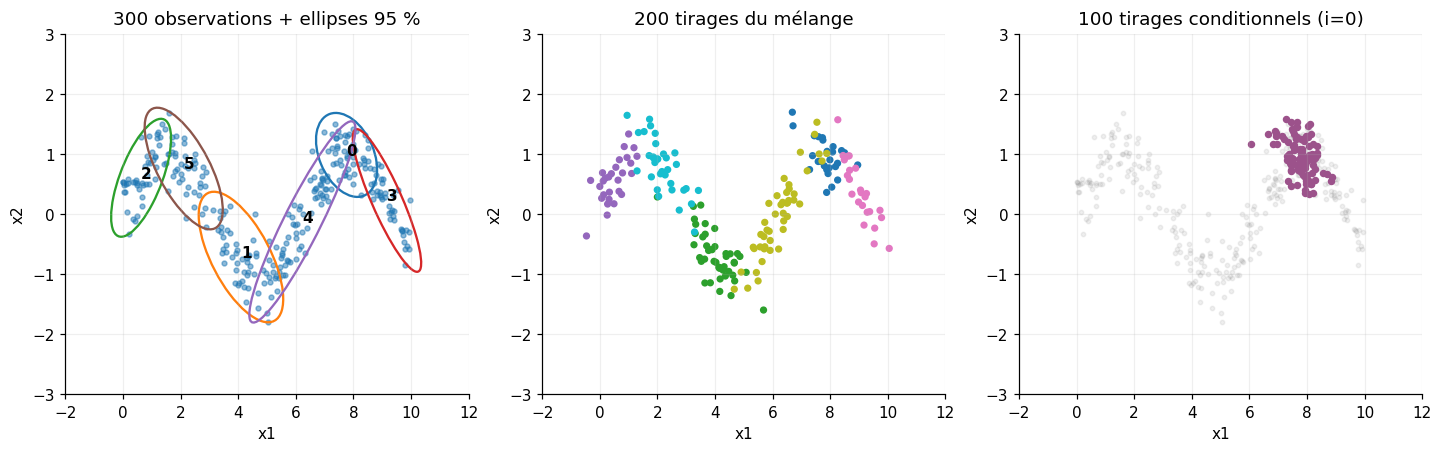

GMM 2D : convergence True itérations 9
Poids des six composantes : [0.13701 0.17432 0.1406  0.15172 0.23956 0.1568 ]
Points globaux avec x1 hors [0,10] : 3
Partie 1 : tous les contrôles ont réussi.


In [6]:
from sklearn.mixture import GaussianMixture
from matplotlib.patches import Ellipse
x1=rng.uniform(0,10,300); x2=np.sin(x1)+rng.normal(0,np.sqrt(.1),300)
X2=np.column_stack([x1,x2])
gmm2=GaussianMixture(n_components=6,covariance_type='full',n_init=3,random_state=42,reg_covar=1e-6).fit(X2)
assert gmm2.converged_
global_sample,component_labels=gmm2.sample(200)
conditional=rng.multivariate_normal(gmm2.means_[0],gmm2.covariances_[0],100)
assert global_sample.shape==(200,2) and conditional.shape==(100,2)
fig,ax=plt.subplots(1,3,figsize=(13,4),layout='constrained')
ax[0].scatter(*X2.T,s=10,alpha=.5)
rad=np.sqrt(-2*np.log(.05))
for k in range(6):
    eig,E=np.linalg.eigh(gmm2.covariances_[k]);idx=np.argsort(eig)[::-1];eig=eig[idx];E=E[:,idx]
    angle=np.degrees(np.arctan2(E[1,0],E[0,0]))
    ax[0].add_patch(Ellipse(gmm2.means_[k],2*rad*np.sqrt(eig[0]),2*rad*np.sqrt(eig[1]),angle=angle,fill=False,lw=1.5,edgecolor=f'C{k}'))
    ax[0].text(*gmm2.means_[k],str(k),weight='bold')
ax[1].scatter(*global_sample.T,c=component_labels,cmap='tab10',s=14)
ax[2].scatter(*X2.T,s=8,alpha=.12,color='gray');ax[2].scatter(*conditional.T,s=15,color='#9C528B')
for a,title in zip(ax,['300 observations + ellipses 95 %','200 tirages du mélange','100 tirages conditionnels (i=0)']):
    a.set(xlabel='x1',ylabel='x2',title=title,xlim=(-2,12),ylim=(-3,3))
save(fig,'07_gmm_sinus_generation')
print('GMM 2D : convergence',gmm2.converged_,'itérations',gmm2.n_iter_)
print('Poids des six composantes :',gmm2.weights_)
print('Points globaux avec x1 hors [0,10] :',int(np.sum((global_sample[:,0]<0)|(global_sample[:,0]>10))))
metrics={
 'bernoulli':{'N':1000,'vrai':.7,'mle':p_mle,'direct':hb[-1,1],'sigmoide':hsig[-1,1],'nll':hb[-1,2]},
 'univariee':{'N':2000,'mu_vrai':2.,'sigma_vrai':1.5,'mu_est':hu[-1,1],'sigma_est':hu[-1,2],'mu_mle':mu_mle,'sigma_mle':sigma_mle,'nll':hu[-1,3]},
 'multivariee':{'N':2000,'mu_vrai':mu_true.tolist(),'mu_est':mu3_est.tolist(),'cov_vraie':cov_true.tolist(),'cov_est':cov3_est.tolist(),'erreur_cov_mle_max':float(np.max(abs(cov3_est-cov3_mle)))},
 'em':{'N':6000,'K':3,'poids_vrais':weights_true.tolist(),'poids_est':pi_aligned.tolist(),'moyennes_vraies':means_true.tolist(),'moyennes_est':means_aligned.tolist(),'cov_vraies':covs_true.tolist(),'cov_est':covs_aligned.tolist(),'permutation':list(perm),'iterations':len(hll)-1,'log_vraisemblance':float(hll[-1]),'min_gain':float(np.diff(hll).min())},
 'sinus':{'N':300,'K':6,'variance_bruit':.1,'sample_global':200,'sample_conditionnel':100,'iterations':int(gmm2.n_iter_),'converged':bool(gmm2.converged_)}}
Path('metriques_partie1.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
np.savez_compressed('donnees_partie1.npz',bernoulli=xb.numpy(),gaussienne=xu.numpy(),gaussienne3d=X3,gmm3d=Xg,gmm_labels=z,sinus=X2,generation_globale=global_sample,generation_conditionnelle=conditional)
print('Partie 1 : tous les contrôles ont réussi.')


## Réflexion
L’estimation choisit les paramètres qui expliquent les observations ; la génération produit de nouvelles observations depuis une loi estimée. Une bonne optimisation peut atteindre le MLE sans retrouver exactement les paramètres vrais à taille finie. EM ne garantit pas le maximum global ; les essais et l’alignement évitent de confondre minimum local et permutation des composantes. Les ellipses et échantillons montrent ce qu’un mélange peut représenter, mais aussi ses limites de support et de courbure.